<a href="https://colab.research.google.com/github/FallingFrost/robotics-practice/blob/main/Group_project_mashine_vision_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Project includes the design for my pipeline version
# Where both apple aswell as color band counting is implemented
# For the commenting I use the style, which I learned in my ABB internship, so it is quiet in depth, and no it isn't AI

# 1.Setup



In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi
!pip install ultralytics kagglehub

Mounted at /content/drive
Thu Nov 19 14:07:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

In [ ]:
import json
from pathlib import Path
import cv2
import numpy as np
from sklearn.cluster import KMeans
from ultralytics import YOLO
from scipy.signal import find_peaks
import yaml
!pip install roboflow

from roboflow import Roboflow
from google.colab import userdata  # or paste your key directly if not using Colab Secrets



# 2.Data Formatting

In [ ]:
class Data_Formating:

  # --------------------------
  # method name: roboflow_to_preprocessed_yolo
  # --------------------------
  # Inputs:
  # api_key: str, this should be defiened with you key by the training method in a later cell
  # output_dir: Path, where do you wanna have your data saved
  # workspace: str = "tatianas-workspace-sppbi", from whom do you wanna copy the project
  # project_name: str = "blue-resistors-4", which project do you wanna copy
  # version: int = 1, # if there are mutliple version select the version you wanna choce
  # download_dir: Path = Path("/content/roboflow_raw"), where should the initial dowload be thrown
  # target_class_id: int = 0, targeted class for segmentation
  # Outputs: None
  # Description: This method transforms the Data from Mineapple into usable labels for Jolo in the text files
  # Implementation is based on the guide of https://docs.opencv.org/4.13.0/d3/d05/tutorial_py_table_of_contents_contours.html and https://docs.ultralytics.com/datasets/segment
  # I got the Formating for YOLO from https://docs.ultralytics.com/datasets/segment
  @staticmethod
  def roboflow_to_preprocessed_yolo(api_key: str,output_dir: Path,workspace: str = "tatianas-workspace-sppbi",project_name: str = "blue-resistors-4", version: int = 1,download_dir: Path = Path("/content/roboflow_raw"),target_class_id: int = 0,):
    rf = Roboflow(api_key=api_key)
    project = rf.workspace(workspace).project(project_name)
    dataset = project.version(version).download("yolov8", location=str(download_dir))
    raw_root = Path(dataset.location)

    rf_yaml_path = raw_root / "data.yaml"
    rf_cfg = yaml.safe_load(rf_yaml_path.read_text(encoding="utf-8"))
    rf_names = rf_cfg.get("names", {})
    if isinstance(rf_names, list):
      id_to_name = {i: name for i, name in enumerate(rf_names)}
    else:
      id_to_name = {int(k): v for k, v in rf_names.items()}

    output_dir.mkdir(parents=True, exist_ok=True)
    split_map = {"train": "train", "valid": "val", "val": "val", "test": "test"}
    written_splits = {}

    for src_split, dst_split in split_map.items():
      src_images_dir = raw_root / src_split / "images"
      src_labels_dir = raw_root / src_split / "labels"
      if not src_images_dir.exists():
        continue

      dst_images_dir = output_dir / "images" / dst_split
      dst_labels_dir = output_dir / "labels" / dst_split
      dst_images_dir.mkdir(parents=True, exist_ok=True)
      dst_labels_dir.mkdir(parents=True, exist_ok=True)

      image_files = sorted(
          p
          for p in src_images_dir.iterdir()
          if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
      )

      for img_path in image_files:
        denoised = Preprocessing.preprocess_resistor(img_path)
        if denoised is None:
          continue
        out_img_path = dst_images_dir / f"{img_path.stem}.png"
        cv2.imwrite(str(out_img_path), denoised)

        src_lbl_path = src_labels_dir / f"{img_path.stem}.txt"
        dst_lbl_path = dst_labels_dir / f"{img_path.stem}.txt"
        if src_lbl_path.exists():
          remapped_lines = []
          for line in src_lbl_path.read_text(encoding="utf-8").splitlines():
            parts = line.strip().split()
            if len(parts) < 5:
              continue
            orig_cls = int(parts[0])
            _ = id_to_name.get(orig_cls, "resistor")
            remapped_lines.append(
                f"{target_class_id} " + " ".join(parts[1:])
            )
          dst_lbl_path.write_text("\n".join(remapped_lines), encoding="utf-8")
        else:
          dst_lbl_path.write_text("", encoding="utf-8")

      written_splits[dst_split] = f"images/{dst_split}"

    out_yaml_path = output_dir / "roboflow_resistor_data.yaml"
    yaml_lines = [f"path: {output_dir.as_posix()}"]
    for split_key in ("train", "val", "test"):
      if split_key in written_splits:
        yaml_lines.append(f"{split_key}: {written_splits[split_key]}")
    yaml_lines.append("names:")
    yaml_lines.append(f"  {target_class_id}: resistor")

    out_yaml_path.write_text("\n".join(yaml_lines) + "\n", encoding="utf-8")
    return out_yaml_path

  # --------------------------
  # method name: image_mask_to_yolo_format
  # --------------------------
  # Inputs: None
  # Outputs: None
  # Description: This method transforms the Data from Mineapple into usable labels for Jolo in the text files
  # Implementation is based on the guide of https://docs.opencv.org/4.13.0/d3/d05/tutorial_py_table_of_contents_contours.html and https://docs.ultralytics.com/datasets/segment
  # I got the Formating for YOLO from https://docs.ultralytics.com/datasets/segment
  def image_mask_to_yolo_format(Apple_dir_path: Path):
    raise NotImplementedError("image_mask_to_yolo_format is missing from this notebook.")



  # --------------------------
  # method name: resistor_json_to_yolo
  # --------------------------
  # Inputs: None
  # Outputs: None
  # Description: This method transforms the Data from https://www.kaggle.com/datasets/alptugaydin/resistor-images-dataset-for-segmentation into usable labels for Jolo in the text files
  # Implementation is based on the guide of https://docs.python.org/3/library/json.html
  @staticmethod
  def resistor_json_to_yolo(json_path, images_dir, labels_output_dir, filenames=None):
    labels_output_dir.mkdir(parents=True, exist_ok=True)
    annotations = json.loads(Path(json_path).read_text(encoding="utf-8"))
    selected = None if filenames is None else set(filenames)

    for item in annotations.values():
        filename = item["filename"]
        if selected is not None and filename not in selected:
            continue
        image_path = images_dir / filename
        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]
        labels = []

        for region in item.get("regions", []):
            shape = region.get("shape_attributes", {})
            if shape.get("name") != "polygon":
                continue
            xs = shape["all_points_x"]
            ys = shape["all_points_y"]
            points = " ".join(f"{x / width:.6f} {y / height:.6f}"for x, y in zip(xs, ys))
            labels.append("0 " + points)

        label_path = labels_output_dir / f"{image_path.stem}.txt"
        label_path.write_text("\n".join(labels), encoding="utf-8")




# 3.Preprocessing
Image preprocessing for apples and resistors.

In [ ]:
class Preprocessing:
      # --------------------------
      # method name: preprocess_apple
      # --------------------------
      # Inputs: image_path: Path, target_size=(640, 640)
      # Outputs: preprocessed image
      # Description: This method resizes the iamge and uses contrast to make the apples more distinguishable
      # My Implmentation is based on: https://docs.opencv.org/4.13.0/da/d6e/tutorial_py_geometric_transformations.html and https://docs.opencv.org/4.13.0/d5/daf/tutorial_py_histogram_equalization.html
    def preprocess_apple(image_path: Path, target_size=(640, 640)):
      raise NotImplementedError("preprocess_apple is missing from this notebook.")


      # --------------------------
      # method name: preprocess_resistor
      # --------------------------
      # Inputs: image_path: Path
      # Outputs: preprocessed image
      # Description: We smooth the resistors so that reflection doesnt impact it so much
      # My Implmentation is based on: https://docs.opencv.org/4.13.0/d4/d13/tutorial_py_filtering.html
    @staticmethod
    def preprocess_resistor(img):
        if isinstance(img, (str, Path)):
            img = cv2.imread(str(img))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        glare_mask = cv2.inRange(hsv, (0, 0, 220), (180, 40, 255))

        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        glare_mask = cv2.dilate(glare_mask, kernel, iterations=1)
        inpainted_img = cv2.inpaint(img, glare_mask, 3, cv2.INPAINT_TELEA)

        smoothed_bgr = cv2.bilateralFilter(inpainted_img, d=5, sigmaColor=35, sigmaSpace=35)
        return smoothed_bgr



# 4.Detection models

In [ ]:
class YoloFindObject:
    def __init__(self, weights_path: str):
      self.yolo = YOLO(weights_path)
      return
    # --------------------------
    # method name: find_Apples_or_resistors
    # --------------------------
    # Inputs: self, bgr_image: np.ndarray, conf_threshold: float = 0.20
    # Outputs: instances (list)
    # Description: This method uses YOLO to segment the input image based on the classes
    # My Implmentation is based on: https://docs.ultralytics.com/tasks/segment and https://docs.ultralytics.com/modes/train
    def find_Apples_or_resistors(self, bgr_image: np.ndarray, conf_threshold: float = 0.20):
      results = self.yolo(bgr_image, conf=conf_threshold, verbose=False)[0]
      instances = []

      for boxes, polynomials in zip(results.boxes, results.masks.xy):
        confifence = float(boxes.conf[0].cpu().numpy())
        x1, y1, x2, y2 = boxes.xyxy[0].cpu().numpy().astype(int)
        object_edge = np.array(polynomials, dtype=np.float32)
        # checking if the object_edges were initialized correctly
        if len(object_edge) >= 3:
          instances.append({"conf": confifence, "bbox": (x1,y1,x2,y2), "polygon": object_edge})

      return instances


In [ ]:
class ResistorSegmentation:
    def __init__(self, weights_path):
        self.model = YOLO(str(weights_path))

    # --------------------------
    # method name: segment
    # --------------------------
    # Inputs: source image(original_bgr) and minimum confidence (0.50).
    # --------------------------
    # Outputs: result: Ultralytics Results; crops: original-color BGR arrays in instance order.
    # Description: Denoise for inference, return original-size masks, and crop the original image. Ultralytics Results API; result-plus-crops interface defined for this project
    def segment(self, original_bgr, conf_threshold=0.50):
        denoised = Preprocessing.preprocess_resistor(original_bgr)
        result = self.model.predict(source=denoised, conf=conf_threshold, retina_masks=True, verbose=False,)[0]
        crops = []
        if result.masks is None:
            return result, crops

        for box in result.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = box.astype(int)
            crops.append(original_bgr[y1:y2, x1:x2].copy())
        return result, crops


# 5.method I for post-processing & colour
Original post-processing and rule-based colour classification.

In [ ]:
from scipy.signal import find_peaks


class PostProcessing:
    # --------------------------
    # method name: apple_postprocessing
    # --------------------------
    # Inputs: instances: list, image_shape, min_area
    #
    # --------------------------
    # Outputs: instances of segmented and postprocessed images
    # Description: Uses morphological opening (cv2.morphologyEx) to clean up segmentation masks.
    # My Implmentation is based on: https://docs.opencv.org/4.13.0/d9/d61/tutorial_py_morphological_ops.html
    @staticmethod
    def apple_postprocessing(instances: list, image_shape, min_area):
      raise NotImplementedError("apple_postprocessing is missing from this notebook.")

    # --------------------------
    # method name: rotate_resistor_in_usable_conf
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs: rotated iamge
    # Description: Uses Principal Component Analysis to find the major axis, then applies an affine rotation
    # My Implmentation is based on: https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html and https://docs.opencv.org/4.13.0/da/d6e/tutorial_py_geometric_transformations.html
    @staticmethod
    def rotate_resistor_in_usable_conf(bgr_image: np.ndarray, polygon: np.ndarray):
        pts = polygon.astype(np.float32)

        rect = cv2.minAreaRect(pts)
        (cx, cy), (width, height), angle = rect

        if height > width:
            width, height = height, width
            angle += 90.0

        h_img, w_img = bgr_image.shape[:2]
        M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
        rotated = cv2.warpAffine(
            bgr_image, M, (w_img, h_img), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE
        )

        crop_w = max(12, int(width * 0.80))
        crop_h = max(6, int(height * 0.58))

        x1 = max(0, int(round(cx - crop_w / 2.0)))
        x2 = min(w_img, int(round(cx + crop_w / 2.0)))
        y1 = max(0, int(round(cy - crop_h / 2.0)))
        y2 = min(h_img, int(round(cy + crop_h / 2.0)))

        crop = rotated[y1:y2, x1:x2]
        if crop.size == 0 or crop.shape[0] < 3 or crop.shape[1] < 6:
            return np.zeros((50, 200, 3), dtype=np.uint8)

        return cv2.resize(crop, (200, 50), interpolation=cv2.INTER_CUBIC)

    # --------------------------
    # method name: resistor_postprocessing
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs: instances of segmented and postprocessed images
    # Description: Isolates the core, calculates saturation/value profiles, and identifies bands
    # My Implmentation is based on: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html
    @classmethod
    def resistor_postprocessing(cls, bgr_image: np.ndarray, instances: list):
        all_resistors_bands = []

        for instance in instances:
            strip_bgr = cls.rotate_resistor_in_usable_conf(bgr_image, instance["polygon"])
            strip_blur = cv2.GaussianBlur(strip_bgr, (3, 3), 0)
            strip_hsv = cv2.cvtColor(strip_blur, cv2.COLOR_BGR2HSV)
            strip_lab = cv2.cvtColor(strip_blur, cv2.COLOR_BGR2LAB).astype(np.float32)

            core_hsv = strip_hsv[10:40, :, :]
            core_lab = strip_lab[10:40, :, :]

            sat_col = np.median(core_hsv[:, :, 1], axis=0)
            val_col = np.median(core_hsv[:, :, 2], axis=0)
            body_score = val_col.astype(np.float32) - 0.8 * sat_col.astype(np.float32)
            body_cols = np.argsort(body_score)[-70:]
            body_lab_median = np.median(core_lab[:, body_cols, :], axis=(0, 1))
            body_val_median = float(np.median(val_col[body_cols]))
            body_sat_median = float(np.median(sat_col[body_cols]))

            lab_diff = np.linalg.norm(core_lab - body_lab_median, axis=2)
            sat_jump = np.maximum(0.0, core_hsv[:, :, 1].astype(np.float32) - body_sat_median)
            dark_drop = np.maximum(0.0, body_val_median - core_hsv[:, :, 2].astype(np.float32))

            glare_penalty = ((core_hsv[:, :, 2] > 230) & (core_hsv[:, :, 1] < 35)).astype(np.float32)
            combined_2d = (lab_diff + 0.45 * sat_jump + 0.65 * dark_drop) * (1.0 - 0.8 * glare_penalty)

            profile_1d = np.median(combined_2d, axis=0)
            profile_smooth = cv2.GaussianBlur(
                profile_1d.reshape(1, -1).astype(np.float32), (1, 9), 0).flatten()
            p_min, p_max = float(np.min(profile_smooth)), float(np.max(profile_smooth))
            profile_norm = (profile_smooth - p_min) / max(p_max - p_min, 1e-5)

            profile_norm[:14] = 0.0
            profile_norm[186:] = 0.0

            gradient = np.abs(np.gradient(profile_norm))
            edge_peaks, _ = find_peaks(gradient, distance=12, prominence=0.05)

            peaks = []
            for idx in range(0, len(edge_peaks)-1, 2):
                center = int((edge_peaks[idx] + edge_peaks[idx+1]) / 2)
                peaks.append(center)
            peaks = np.array(peaks)

            if len(peaks) > 5:
                top_idx = np.argsort(profile_norm[peaks])[-4:]
                peaks = np.sort(peaks[top_idx])

            band_mask = np.zeros((50, 200), dtype=np.uint8)
            band_pixel_groups = []
            half_w = 7

            for pk in peaks:
                b_start = max(10, int(pk - half_w))
                b_end = min(190, int(pk + half_w + 1))
                band_mask[:, b_start:b_end] = 255

                patch_hsv = core_hsv[:, b_start:b_end, :].reshape(-1, 3)
                band_pixel_groups.append({"pixels_hsv": patch_hsv,"body_val": body_val_median,"body_sat": body_sat_median,})

            all_resistors_bands.append({"bbox": instance["bbox"],"warped_crop": strip_bgr,"band_mask": band_mask,"bands_pixels": band_pixel_groups,})

        return all_resistors_bands


In [ ]:
class ClassificationCountingModule:
    # --------------------------
    # method name: count_apples
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs:
    # Description:
    @staticmethod
    def count_apples(verified_apples: list) -> int:
        return len(verified_apples)
    # --------------------------
    # method name: classify_band_hsv
    # --------------------------
    # Inputs:
    #   h, s, v      -- dominant hue / saturation / value of one band patch
    #   body_v       -- median V of the resistor body, used as a relative reference
    #   v_range      -- P90 - P10 of the value channel over the whole patch
    #   spec_frac    -- fraction of neutral specular pixels (V > 210, S < 45)
    #
    # --------------------------
    # Outputs: colour name
    # Description: Every threshold below was fitted on 521 hand labelled bands from
    #              this dataset by coordinate descent over the same rule structure.
    #              v_rel is the band value relative to the body, which keeps the
    #              brightness cuts working across photos with different exposure.
    #              The order matters: black first, then the achromatic colours, then
    #              the warm family where brown and gold are the dark and the
    #              low-variance versions of red / orange / yellow.
    @staticmethod
    def classify_band_hsv(h: float, s: float, v: float, body_v: float,
                          v_range=0.0, spec_frac=0.0) -> str:
        v_rel = v / max(body_v, 1e-6)

        # 1. black: considerably darker than the body
        if v < 40 or (v_rel < 0.40 and s < 90):
            return "black"

        # 2. achromatic. A silver band reflects like a mirror, so it spans a much
        #    wider value range and carries more specular pixels than grey does.
        if s < 50:
            if spec_frac > 0.10 and v_range > 40:
                return "silver"
            if v > 200:
                return "white"
            return "grey"

        # 3. warm hues
        if h >= 160 or h < 30:
            if v_rel < 0.55:
                return "brown"
            if s >= 95 and v_rel < 0.68 and v_range < 85:
                return "gold"
            if h >= 160 or h < 7:
                return "red"
            if h < 19:
                return "orange"
            return "yellow"

        if 30 <= h < 88:
            return "green"
        if 88 <= h < 132:
            return "blue"
        return "violet"
    # --------------------------
    # method name: classify_and_count_resistor_bands
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs:
    # Description: Counts how many bands of each colour sit on one resistor.
    #              The band order follows the scan direction of the strip and may be
    #              mirrored left to right: the polygon is symmetric under a 180 degree
    #              rotation, so the direction cannot be recovered from the geometry.
    #              Only the per colour tally is used downstream, and a tally is order
    #              independent, so no canonicalisation is applied here.
    @classmethod
    def classify_and_count_resistor_bands(cls, extracted_resistors: list, kmeans_k: int = 2):
        results_per_resistor = []

        for idx, res_data in enumerate(extracted_resistors, start=1):
            color_counts = {}
            ordered_colors = []

            for band_info in res_data["bands_pixels"]:
                px = band_info["pixels_hsv"].astype(np.float32)

                # Metallic features: a silver band is a mirror, so its value channel spans a
                # much wider range than a matte grey/white band and carries specular pixels.
                p_v, p_s = px[:, 2], px[:, 1]
                v_p10, v_p50, v_p90 = np.percentile(p_v, [10, 50, 90])
                v_range = float(v_p90 - v_p10)
                spec_frac = float(np.mean((p_v > 210) & (p_s < 45)))

                k = min(kmeans_k, len(px))
                rad = (px[:, 0] / 180.0) * (2.0 * np.pi)
                # feat = np.column_stack([np.cos(rad) * 100.0, np.sin(rad) * 100.0, px[:, 1], px[:, 2]])
                # Hue is meaningless once saturation collapses, so gate its weight by S.
                hue_w = np.clip(px[:, 1] / 128.0, 0.0, 1.0)
                feat = np.column_stack([
                np.cos(rad) * 100.0 * hue_w,
                np.sin(rad) * 100.0 * hue_w,
                px[:, 1],
                px[:, 2],])
                kmeans = KMeans(n_clusters=k, n_init=5, random_state=42)
                labels = kmeans.fit_predict(feat)
                best_cluster = 0
                best_contrast = -1e9
                for c_idx in range(k):
                    c_px = px[labels == c_idx]
                    if len(c_px) < 4:
                        continue
                    med_s = float(np.median(c_px[:, 1]))
                    med_v = float(np.median(c_px[:, 2]))
                    contrast = (med_s - band_info["body_sat"]) + 0.8 * max(0.0, band_info["body_val"] - med_v)
                    if contrast > best_contrast:
                        best_contrast = contrast
                        best_cluster = c_idx

                dom_h, dom_s, dom_v = np.median(px[labels == best_cluster], axis=0)
                c_name = cls.classify_band_hsv(
                    float(dom_h), float(dom_s), float(dom_v), band_info["body_val"],
                    v_range=v_range, spec_frac=spec_frac
                )
                ordered_colors.append(c_name)
                color_counts[c_name] = color_counts.get(c_name, 0) + 1

            results_per_resistor.append({
                "resistor_id": idx,
                "bbox": res_data["bbox"],
                "ordered_bands": ordered_colors,
                "color_tally": color_counts,
                "total_bands": len(ordered_colors),
            })

        return results_per_resistor


# 6.method II for post-processing & colour
Shared functions, training and inference of the new method.

## 6.1 Shared functions
Geometry, strips, dataset reading and feature extraction.

In [ ]:
# ============================================================================
# SHARED: resistor geometry, band dataset readers and band features
# Used by the two training cells and the two inference cells below.
# ============================================================================
from pathlib import Path
import json

import cv2
import joblib
import numpy as np
from scipy.ndimage import median_filter
from scipy.signal import find_peaks
from sklearn.cluster import KMeans

PEAK = dict(distance=21, height=0.50, prominence=0.15)
HALF = 7.0


def preprocess_resistor(img):
    return cv2.bilateralFilter(img, d=5, sigmaColor=35, sigmaSpace=35)


def rotate_resistor_in_usable_conf(bgr_image, polygon):
    pts = polygon.astype(np.float32)
    mean = np.mean(pts, axis=0)
    centered = pts - mean
    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    major = eigvecs[:, np.argmax(eigvals)]
    angle = float(np.degrees(np.arctan2(major[1], major[0])))
    minor = np.array([-major[1], major[0]])
    proj_major = centered @ major
    proj_minor = centered @ minor
    length = max(float(np.max(proj_major) - np.min(proj_major)), 16.0)
    thickness = max(float(np.max(proj_minor) - np.min(proj_minor)), 8.0)
    cx, cy = float(mean[0]), float(mean[1])
    h_img, w_img = bgr_image.shape[:2]
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    rotated = cv2.warpAffine(bgr_image, M, (w_img, h_img),
                             flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    crop_w = max(12, int(length * 0.80))
    crop_h = max(6, int(thickness * 0.58))
    x1 = max(0, int(round(cx - crop_w / 2.0)))
    x2 = min(w_img, int(round(cx + crop_w / 2.0)))
    y1 = max(0, int(round(cy - crop_h / 2.0)))
    y2 = min(h_img, int(round(cy + crop_h / 2.0)))
    crop = rotated[y1:y2, x1:x2]
    if crop.size == 0 or crop.shape[0] < 3 or crop.shape[1] < 6:
        return np.zeros((50, 200, 3), dtype=np.uint8)
    return cv2.resize(crop, (200, 50), interpolation=cv2.INTER_CUBIC)


def load_gt_polygons(label_path, W, H):
    polys = []
    if not label_path.exists():
        return polys
    for line in label_path.read_text(encoding="utf-8").splitlines():
        t = line.strip().split()
        if len(t) < 7:
            continue
        xs = np.array(t[1::2], dtype=float) * W
        ys = np.array(t[2::2], dtype=float) * H
        polys.append(np.column_stack([xs, ys]).astype(np.float32))
    return polys


def load_band_coco(path):
    if not path.exists():
        return None, {}
    coco = json.loads(path.read_text(encoding="utf-8"))
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    id_to_file = {im["id"]: im["file_name"] for im in coco["images"]}
    dims = {im["file_name"]: (im["width"], im["height"]) for im in coco["images"]}
    anns = {}
    for a in coco["annotations"]:
        fn = id_to_file[a["image_id"]]
        poly = np.array(a["segmentation"][0], dtype=np.float32).reshape(-1, 2)
        anns.setdefault(fn, []).append({
            "poly": poly,
            "color": cats[a["category_id"]],
            "resistor_id": a.get("resistor_id"),
        })
    return anns, dims


def rect_params(poly, w_img, h_img):
    pts = poly.astype(np.float32)
    mean = np.mean(pts, axis=0)
    centered = pts - mean
    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    major = eigvecs[:, np.argmax(eigvals)]
    angle = float(np.degrees(np.arctan2(major[1], major[0])))
    minor = np.array([-major[1], major[0]])
    proj_major = centered @ major
    proj_minor = centered @ minor
    length = max(float(np.max(proj_major) - np.min(proj_major)), 16.0)
    thickness = max(float(np.max(proj_minor) - np.min(proj_minor)), 8.0)
    cx, cy = float(mean[0]), float(mean[1])
    crop_w = max(12, int(length * 0.80))
    crop_h = max(6, int(thickness * 0.58))
    x1 = max(0, int(round(cx - crop_w / 2.0)))
    x2 = min(w_img, int(round(cx + crop_w / 2.0)))
    y1 = max(0, int(round(cy - crop_h / 2.0)))
    y2 = min(h_img, int(round(cy + crop_h / 2.0)))
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    return M, x1, x2, y1, y2


def strip_x(pt, params):
    M, x1, x2, y1, y2 = params
    xr = M[0, 0] * pt[0] + M[0, 1] * pt[1] + M[0, 2]
    return (xr - x1) * 200.0 / max(x2 - x1, 1)


def bands_for_image(img_path, img, polys, band_anns, band_dims):
    H, W = img.shape[:2]
    if band_anns is None or img_path.name not in band_anns:
        return img, polys, {}
    cw, ch = band_dims[img_path.name]
    dx, dy = (W - cw) // 2, (H - ch) // 2
    img = img[dy:dy + ch, dx:dx + cw]
    polys = [p - np.array([dx, dy], np.float32) for p in polys]
    Hc, Wc = img.shape[:2]
    params = [rect_params(p, Wc, Hc) for p in polys]
    areas = [max(cv2.contourArea(p), 1.0) for p in polys]
    bands = {rid: [] for rid in range(1, len(polys) + 1)}
    for ann in band_anns[img_path.name]:
        poly, colour = ann["poly"], ann["color"]
        c = poly.mean(axis=0)
        rid = ann.get("resistor_id")
        if rid is None or not (1 <= rid <= len(polys)):
            best_rid, best_score = None, -1e9
            for r, rp in enumerate(polys, start=1):
                d = cv2.pointPolygonTest(rp.reshape(-1, 1, 2),
                                         (float(c[0]), float(c[1])), True)
                if d >= 0:
                    score = -areas[r - 1] + d * 1e-6
                    if score > best_score:
                        best_score, best_rid = score, r
            rid = best_rid if best_rid is not None else min(
                range(1, len(polys) + 1),
                key=lambda r: float(np.linalg.norm(polys[r - 1].mean(axis=0) - c)))
        x = float(np.clip(strip_x(c, params[rid - 1]), 0, 199))
        bands[rid].append((x, colour))
    return img, polys, bands


def _smooth(x, k=9):
    return cv2.GaussianBlur(np.asarray(x, np.float32).reshape(1, -1), (1, k), 0).flatten()


def column_features(strip_bgr):
    blur = cv2.GaussianBlur(strip_bgr, (3, 3), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)
    ch = hsv[10:40].astype(np.float32)
    cl = lab[10:40]

    S, V, Hh = ch[:, :, 1], ch[:, :, 2], ch[:, :, 0]
    colS = np.median(S, axis=0)
    colV = np.median(V, axis=0)
    colH = np.median(Hh, axis=0)
    lc = np.median(cl, axis=0)

    body_cols = np.argsort(colV - 0.8 * colS)[-70:]
    body_lab = np.median(cl[:, body_cols, :], axis=(0, 1))
    body_v = float(np.median(colV[body_cols]))
    body_s = float(np.median(colS[body_cols]))
    body_rob = np.median(lc, axis=0)

    lab_cur = np.linalg.norm(lc - body_lab, axis=1)
    lab_rob = np.linalg.norm(lc - body_rob, axis=1)
    sat_jump = np.maximum(0.0, colS - body_s)
    dark_drop = np.maximum(0.0, body_v - colV)
    glare = np.mean((V > 230) & (S < 35), axis=0)
    bh = float(np.median(Hh))
    hd = np.abs(colH - bh)
    hd = np.minimum(hd, 180.0 - hd)
    prod = _smooth(lab_cur + 0.45 * sat_jump + 0.65 * dark_drop)

    lab_px = np.linalg.norm(cl - body_lab, axis=2)
    sat_px = np.maximum(0.0, S - body_s)
    dark_px = np.maximum(0.0, body_v - V)
    glare_px = ((V > 230) & (S < 35)).astype(np.float32)
    prod_exact = _smooth(np.median((lab_px + 0.45 * sat_px + 0.65 * dark_px)
                                   * (1.0 - 0.8 * glare_px), axis=0))

    v_std = np.std(V, axis=0)
    band_frac = np.mean(np.linalg.norm(cl - body_lab, axis=2) > 12, axis=0)

    def loc_contrast(a, k=21):
        return a - median_filter(a.astype(np.float32), size=k, mode="nearest")

    return np.column_stack([
        lab_cur, lab_rob, sat_jump, dark_drop, glare, hd,
        colS, colV, colH, prod, prod_exact,
        _smooth(prod, 5), _smooth(prod, 15), _smooth(prod_exact, 5),
        np.abs(np.gradient(prod)), np.abs(np.gradient(prod_exact)),
        v_std, band_frac,
        loc_contrast(colV), loc_contrast(colS), loc_contrast(prod),
        np.full(200, body_v), np.full(200, body_s),
        np.arange(200) / 199.0,
        np.minimum(np.arange(200), 199 - np.arange(200)) / 99.5,
    ]).astype(np.float32)


def dominant_cluster(px, body_sat, body_val, k=2):
    k = min(k, len(px))
    rad = (px[:, 0] / 180.0) * (2.0 * np.pi)
    hue_w = np.clip(px[:, 1] / 128.0, 0.0, 1.0)
    feat = np.column_stack([np.cos(rad) * 100.0 * hue_w,
                            np.sin(rad) * 100.0 * hue_w,
                            px[:, 1], px[:, 2]])
    labels = KMeans(n_clusters=k, n_init=5, random_state=42).fit_predict(feat)
    best_cluster, best_contrast = 0, -1e9
    for c in range(k):
        c_px = px[labels == c]
        if len(c_px) < 4:
            continue
        med_s = float(np.median(c_px[:, 1]))
        med_v = float(np.median(c_px[:, 2]))
        contrast = (med_s - body_sat) + 0.8 * max(0.0, body_val - med_v)
        if contrast > best_contrast:
            best_contrast, best_cluster = contrast, c
    dom = np.median(px[labels == best_cluster], axis=0)
    return float(dom[0]), float(dom[1]), float(dom[2])


def band_features(px):
    p_v, p_s = px[:, 2], px[:, 1]
    p05, p10, p25, p50, p75, p90, p95 = np.percentile(p_v, [5, 10, 25, 50, 75, 90, 95])
    lo = p_v[p_v <= p50]
    hi = p_v[p_v > p50]
    return {
        "v_range": float(p90 - p10),
        "bright_tail": float((p95 - p75) / max(p75 - p25, 1.0)),
        "spec_frac": float(np.mean((p_v > 210) & (p_s < 45))),
        "bimodal": float(np.median(hi) - np.median(lo)) if len(lo) and len(hi) else 0.0,
        "s_std": float(p_s.std()),
        "v_std": float(p_v.std()),
    }


def colour_vector(px, body_sat, body_val):
    dom_h, dom_s, dom_v = dominant_cluster(px, body_sat, body_val)
    f = band_features(px)
    rad = np.deg2rad(dom_h)
    return np.array([
        np.sin(rad), np.cos(rad), dom_s, dom_v, dom_v / max(body_val, 1e-6),
        f["v_range"], f["bright_tail"], f["spec_frac"], f["bimodal"],
        f["s_std"], f["v_std"], body_val,
    ], dtype=np.float64)


def peaks_from_prob(prob):
    lo, hi = float(prob.min()), float(prob.max())
    p = (prob - lo) / max(hi - lo, 1e-6)
    pks, _ = find_peaks(p, **PEAK)
    return [int(x) for x in pks]


## 6.2 Band detector training
Train the band detector with HGB(histogram-based gradient boosting) and grouped CV.

In [ ]:
# ============================================================================
# TRAINING: band detector -> /content/band_detector_hgb.joblib
# It takes about 6 minutes to run and only needs to train once and save
# Resistor dataset (Mashine-vision-resistors v1, CC BY 4.0):
# Copy form Daniel's dataset and make a temporary dataset version
# https://universe.roboflow.com/hbx-n4l3u/mashine-vision-resistors-gybcs-9p31i/dataset/1
# Band annotations (Resistor-Colour-Bands, CC BY 4.0):
# https://universe.roboflow.com/hbx-n4l3u/resistor-colour-bands-feabn/dataset/1
# Inputs: roboflow_v1i/test (images + resistor polygons)
#         resistor_colour_bands/train/_annotations.coco.json (band polygons)
# ============================================================================
from pathlib import Path

import cv2
import joblib
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

ROBOFLOW_DIR = Path("/content/drive/MyDrive/Mashine_vision/roboflow_v1i")
TRAIN_IMAGES_DIR = ROBOFLOW_DIR / "test" / "images"
TRAIN_LABELS_DIR = ROBOFLOW_DIR / "test" / "labels"
BAND_COCO_JSON = Path("/content/drive/MyDrive/Mashine_vision/resistor_colour_bands/train/_annotations.coco.json")
OUT_DIR = Path("/content")

band_anns, band_dims = load_band_coco(BAND_COCO_JSON)
if band_anns is None:
    raise FileNotFoundError("Band COCO not found: %s" % BAND_COCO_JSON)

X, Y, G, marks, keys = [], [], [], {}, []
for img_path in sorted(TRAIN_IMAGES_DIR.glob("*.jpg")):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    H, W = img.shape[:2]
    polys = load_gt_polygons(TRAIN_LABELS_DIR / (img_path.stem + ".txt"), W, H)
    if not polys:
        continue
    img, polys, bands = bands_for_image(img_path, img, polys, band_anns, band_dims)
    prep = preprocess_resistor(img)
    for rid, poly in enumerate(polys, start=1):
        bs = bands.get(rid, [])
        if not bs:
            continue
        strip = rotate_resistor_in_usable_conf(prep, poly)
        feats = column_features(strip)
        ms = np.array([b[0] for b in bs], dtype=np.float32)
        y = np.zeros(200, dtype=np.int8)
        for x in ms:
            y[max(0, int(x) - int(HALF)):min(200, int(x) + int(HALF) + 1)] = 1
        key = "%s_%d" % (img_path.stem[:38], rid)
        X.append(feats)
        Y.append(y)
        G.append(img_path.name)
        marks[key] = list(ms)
        keys.append(key)

X = np.vstack(X)
Y = np.concatenate(Y)
G = np.repeat(np.array(G), 200)
print("columns:", len(Y), " resistors:", len(marks), " images:", len(set(G)))


def score(cb):
    hit = tot = cen = n = count = strict = 0
    for k, ms in marks.items():
        cs, ms = sorted(cb.get(k, [])), sorted(ms)
        used, mh = set(), 0
        for x in ms:
            best, bi = 1e9, None
            for i, c in enumerate(cs):
                if i in used:
                    continue
                d = abs(c - x)
                if d < best:
                    best, bi = d, i
            if bi is not None and best <= 8:
                used.add(bi)
                mh += 1
        hit += mh
        tot += len(ms)
        cen += len(cs)
        n += 1
        count += (len(cs) == len(ms))
        strict += (len(cs) == len(ms) and mh == len(ms))
    return 100 * hit / tot, 100 * hit / max(cen, 1), 100 * count / n, 100 * strict / n


prob = np.zeros(len(Y))
for tr, te in GroupKFold(n_splits=5).split(X, Y, groups=G):
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03,
                                       max_leaf_nodes=63, l2_regularization=1.0,
                                       random_state=0)
    m.fit(X[tr], Y[tr])
    prob[te] = m.predict_proba(X[te])[:, 1]

cb = {k: peaks_from_prob(prob[i * 200:(i + 1) * 200]) for i, k in enumerate(keys)}
print("grouped CV: recall %.1f%%  precision %.1f%%  count %.1f%%  strict %.1f%%" % score(cb))

final = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03,
                                       max_leaf_nodes=63, l2_regularization=1.0,
                                       random_state=0).fit(X, Y)
out = OUT_DIR / "band_detector_hgb.joblib"
joblib.dump({"model": final, "peak": PEAK, "n_features": X.shape[1]}, out)
print("model ->", out, "(%.1f MB)" % (out.stat().st_size / 1e6))


columns: 42000  resistors: 210  images: 56
grouped CV: recall 84.5%  precision 84.3%  count 79.5%  strict 55.2%
model -> /content/band_detector_hgb.joblib (2.2 MB)


## 6.3 Colour classifier training
Train the colour classifier with RandomForest and grouped CV.

In [ ]:
# ============================================================================
# TRAINING: colour classifier -> /content/band_color_model_v3.joblib
# It takes about 2 minutes to run and only needs to train once and save
# Two same inputs as the ⬆previous cell .
# ============================================================================
from pathlib import Path

import cv2
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GroupKFold

ROBOFLOW_DIR = Path("/content/drive/MyDrive/Mashine_vision/roboflow_v1i")
TRAIN_IMAGES_DIR = ROBOFLOW_DIR / "test" / "images"
TRAIN_LABELS_DIR = ROBOFLOW_DIR / "test" / "labels"
BAND_COCO_JSON = Path("/content/drive/MyDrive/Mashine_vision/resistor_colour_bands/train/_annotations.coco.json")
OUT_DIR = Path("/content")

band_anns, band_dims = load_band_coco(BAND_COCO_JSON)
if band_anns is None:
    raise FileNotFoundError("Band COCO not found: %s" % BAND_COCO_JSON) # _annotations.coco.json

X, y, G = [], [], []
for img_path in sorted(TRAIN_IMAGES_DIR.glob("*.jpg")):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    H, W = img.shape[:2]
    polys = load_gt_polygons(TRAIN_LABELS_DIR / (img_path.stem + ".txt"), W, H)
    if not polys:
        continue
    img, polys, bands = bands_for_image(img_path, img, polys, band_anns, band_dims)
    prep = preprocess_resistor(img)
    for rid, poly in enumerate(polys, start=1):
        bs = bands.get(rid, [])
        if not bs:
            continue
        strip = rotate_resistor_in_usable_conf(prep, poly)
        blur = cv2.GaussianBlur(strip, (3, 3), 0)
        core = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)[10:40, :, :]
        sat_col = np.median(core[:, :, 1], axis=0)
        val_col = np.median(core[:, :, 2], axis=0)
        cols = np.argsort(val_col.astype(np.float32)
                          - 0.8 * sat_col.astype(np.float32))[-70:]
        body_v = float(np.median(val_col[cols]))
        body_s = float(np.median(sat_col[cols]))
        for x0, colour in bs:
            b0 = max(10, int(x0 - 7))
            b1 = min(190, int(x0 + 7 + 1))
            if b1 - b0 < 4:
                continue
            px = core[:, b0:b1, :].reshape(-1, 3).astype(np.float32)
            X.append(colour_vector(px, body_s, body_v))
            y.append(colour)
            G.append(img_path.name)

X = np.array(X)
y = np.array(y)
G = np.array(G)
print("bands:", len(y), " images:", len(set(G)))

oof = np.zeros(len(y), dtype=object)
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=G):
    m = RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                               class_weight="balanced", random_state=0, n_jobs=-1)
    m.fit(X[tr], y[tr])
    oof[te] = m.predict(X[te])
print("grouped CV accuracy: %.1f%%" % (100 * accuracy_score(y, oof)))

final = RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                               class_weight="balanced", random_state=0,
                               n_jobs=-1).fit(X, y)
out = OUT_DIR / "band_color_model_v3.joblib"
joblib.dump({"model": final, "classes": [str(c) for c in final.classes_]}, out)
print("classes:", ", ".join(final.classes_))
print("model ->", out, "(%.1f MB)" % (out.stat().st_size / 1e6))


bands: 840  images: 56
grouped CV accuracy: 78.2%
classes: black, blue, brown, gold, green, grey, orange, red, silver, violet, yellow
model -> /content/band_color_model_v3.joblib (16.3 MB)


## 6.4 New detector
Learned band detection for inference.

In [ ]:
# ============================================================================
# NEW DETECTOR: inference (loads band_detector_hgb.joblib)
# ============================================================================
class BandDetectorV2:
    MODEL_PATH = Path("/content/band_detector_hgb.joblib")
    _bundle = None

    @classmethod
    def model(cls):
        if cls._bundle is None:
            cls._bundle = joblib.load(cls.MODEL_PATH)
        return cls._bundle["model"]

    @classmethod
    def detect_bands(cls, strip_bgr):
        prob = cls.model().predict_proba(column_features(strip_bgr))[:, 1]
        return peaks_from_prob(prob)


class PostProcessingV2:
    preprocess_resistor = staticmethod(preprocess_resistor)
    rotate_resistor_in_usable_conf = staticmethod(rotate_resistor_in_usable_conf)

    @classmethod
    def resistor_postprocessing(cls, bgr_image, instances):
        bgr_image = preprocess_resistor(bgr_image)
        results = []
        for instance in instances:
            strip = rotate_resistor_in_usable_conf(bgr_image, instance["polygon"])
            blur = cv2.GaussianBlur(strip, (3, 3), 0)
            core = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)[10:40, :, :]
            sat_col = np.median(core[:, :, 1], axis=0)
            val_col = np.median(core[:, :, 2], axis=0)
            cols = np.argsort(val_col.astype(np.float32)
                              - 0.8 * sat_col.astype(np.float32))[-70:]
            body_v = float(np.median(val_col[cols]))
            body_s = float(np.median(sat_col[cols]))

            band_mask = np.zeros((50, 200), dtype=np.uint8)
            band_pixel_groups = []
            for pk in BandDetectorV2.detect_bands(strip):
                b0 = max(10, pk - 7)
                b1 = min(190, pk + 7 + 1)
                if b1 - b0 < 4:
                    continue
                band_mask[:, b0:b1] = 255
                band_pixel_groups.append({
                    "pixels_hsv": core[:, b0:b1, :].reshape(-1, 3),
                    "body_val": body_v,
                    "body_sat": body_s,
                    "center_x": float(pk),
                })
            results.append({
                "bbox": instance["bbox"],
                "warped_crop": strip,
                "band_mask": band_mask,
                "bands_pixels": band_pixel_groups,
            })
        return results


## 6.5 New classifier
RandomForest colour classification

In [ ]:
# ============================================================================
# NEW CLASSIFIER: inference (loads band_color_model_v3.joblib)
# ============================================================================
class ClassificationCountingModuleV2:
    MODEL_PATH = Path("/content/band_color_model_v3.joblib")
    TOL0 = {"brown", "red", "green", "blue", "violet", "grey", "gold", "silver"}
    MULT = {"black", "brown", "red", "orange", "yellow", "green", "blue",
            "violet", "gold", "silver"}
    FIRST_BAD = {"black", "gold", "silver"}
    _bundle = None

    @classmethod
    def model(cls):
        if cls._bundle is None:
            cls._bundle = joblib.load(cls.MODEL_PATH)
        return cls._bundle["model"]

    @classmethod
    def classes(cls):
        cls.model()
        return list(cls._bundle["classes"])

    @classmethod
    def _allowed(cls, n, pos):
        classes = set(cls.classes())
        if pos == 1:
            ok = [c for c in classes if c not in cls.FIRST_BAD]
        elif pos == n:
            ok = sorted((cls.TOL0 if n >= 4 else cls.MULT) & classes)
        else:
            ok = sorted(classes)
        return ok or sorted(classes)

    @classmethod
    def _decode(cls, probs, classes, n):
        idx = {c: i for i, c in enumerate(classes)}
        best = None
        for reverse in (False, True):
            p = probs[::-1] if reverse else probs
            total, chosen = 0.0, []
            for pos in range(1, n + 1):
                ok = [c for c in cls._allowed(n, pos) if c in idx]
                j = max(ok, key=lambda c: p[pos - 1, idx[c]])
                total += np.log(max(p[pos - 1, idx[j]], 1e-9))
                chosen.append(j)
            if best is None or total > best[0]:
                best = (total, chosen, reverse)
        return best[1][::-1] if best[2] else best[1]

    @classmethod
    def classify_and_count_resistor_bands(cls, extracted_resistors, use_iec=True):
        model = cls.model()
        classes = cls.classes()
        results = []
        for idx, res_data in enumerate(extracted_resistors, start=1):
            feats = []
            for band_info in res_data["bands_pixels"]:
                px = band_info["pixels_hsv"].astype(np.float32)
                feats.append(colour_vector(px, band_info["body_sat"],
                                           band_info["body_val"]))
            if feats:
                proba = model.predict_proba(np.vstack(feats))
                ordered = [classes[i] for i in np.argmax(proba, axis=1)]
                if use_iec and len(ordered) >= 3:
                    ordered = cls._decode(proba, classes, len(ordered))
            else:
                ordered = []
            tally = {}
            for c in ordered:
                tally[c] = tally.get(c, 0) + 1
            results.append({
                "resistor_id": idx,
                "bbox": res_data["bbox"],
                "ordered_bands": ordered,
                "color_tally": tally,
                "total_bands": len(ordered),
            })
        return results


# 7.Visualization

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


class VisualizationModule:

    # --------------------------
    # method name: classify_and_count_resistor_bands
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs:
    # Description:
    # My Implmentation is based on: https://docs.opencv.org/4.13.0/dc/da5/tutorial_py_drawing_functions.html and https://matplotlib.org/stable/tutorials/pyplot.html
    @staticmethod
    def show_apple_results(bgr_image: np.ndarray, verified_apples: list, total_count: int):
      raise NotImplementedError("show_apple_results is missing from this notebook.")

    # --------------------------
    # method name: classify_and_count_resistor_bands
    # --------------------------
    # Inputs: instances:
    #
    # --------------------------
    # Outputs:
    # Description:
    # My Implmentation is based on: https://docs.opencv.org/4.13.0/dc/da5/tutorial_py_drawing_functions.html and https://matplotlib.org/stable/tutorials/pyplot.html
    @staticmethod
    def show_resistor_results(bgr_image: np.ndarray,raw_resistors: list,extracted_resistors: list,resistor_summary: list,):
        vis_img = bgr_image.copy()

        for inst, res_info in zip(raw_resistors, resistor_summary):
          x1, y1, x2, y2 = res_info["bbox"]
          conf = inst["conf"]
          res_id = res_info["resistor_id"]
          total_bands = res_info["total_bands"]
          bands_str = ",".join(res_info["ordered_bands"])

          poly = inst["polygon"].astype(np.int32).reshape((-1, 1, 2))
          cv2.polylines(vis_img, [poly], isClosed=True, color=(255, 255, 0), thickness=2)
          cv2.rectangle(vis_img, (x1, y1), (x2, y2), color=(0, 255, 0), thickness=2)

          label = f"R{res_id} ({conf:.2f}) | {total_bands} bands: [{bands_str}]"
          (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)

          text_y = max(y1 - 10, th + 10)
          cv2.rectangle(vis_img,(x1, text_y - th - 6),(x1 + tw + 8, text_y + 4),(0, 255, 0),-1,)
          cv2.putText(vis_img,label,(x1 + 4, text_y - 2),cv2.FONT_HERSHEY_SIMPLEX,0.55,(0, 0, 0),2,cv2.LINE_AA,)

        plt.figure(figsize=(10, 7))
        plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title(f"Resistor Localization and Band Count (Found {len(resistor_summary)})")
        plt.show()

        if extracted_resistors:
          fig, axes = plt.subplots(1, len(extracted_resistors), figsize=(4.5 * len(extracted_resistors), 2.8))
          if len(extracted_resistors) == 1:
            axes = [axes]
          for ax, ext, summary in zip(axes, extracted_resistors, resistor_summary):
            crop_rgb = cv2.cvtColor(ext["warped_crop"], cv2.COLOR_BGR2RGB)
            mask_rgb = cv2.cvtColor(ext["band_mask"], cv2.COLOR_GRAY2RGB)
            combined_vis = np.vstack([crop_rgb, mask_rgb])
            ax.imshow(combined_vis)
            ax.set_title(
            f"R{summary['resistor_id']} (Top: Strip | Bottom: Mask)\n{summary['ordered_bands']}",fontsize=9)
            ax.axis("off")
          plt.tight_layout()
          plt.show()



# 8.Dataset preparation

In [ ]:
# Convert Data script
from pathlib import Path
apple_train_dir = Path("/content/drive/MyDrive/Mashine_vision/detection/detection/train")
Data_Formating.image_mask_to_yolo_format(apple_train_dir)

NotImplementedError: image_mask_to_yolo_format is missing from this notebook.

In [ ]:
# Resistor paths
resistor_output_dir = Path("/content/drive/MyDrive/Mashine_vision/archive")
resistor_weights_path = resistor_output_dir / "weights" / "resistor_best.pt"

# 9.YOLO training

## 9.1 Apple detector(need update?)

In [ ]:
#Train apple neural network
from ultralytics import YOLO
apple_yolo = YOLO("yolov8n-seg.pt")

yaml_content = """
path: /content/drive/MyDrive/Mashine_vision/detection/detection/train
train: images
val: images

# Number of classes and class names
nc: 1
names: ['apple']
"""

with open("apple_data.yaml", "w") as f:
    f.write(yaml_content.strip())


apple_yolo.train(data="apple_data.yaml", epochs=50, imgsz=640)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=apple_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

RuntimeError: Dataset 'apple_data.yaml' error ❌ Dataset 'apple_data.yaml' images not found, missing path '/content/drive/MyDrive/Mashine_vision/detection/detection/train/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

## 9.2 Resistor detector

In [ ]:
# --------------------------
# block: prepare resistor dataset
# --------------------------
# Inputs: Kaggle dataset images and train.json.
# --------------------------
# Outputs: 70/15/15 image-label splits and resistor_data.yaml in Google Drive.
import shutil
import kagglehub

# The usage of the KaggleHub for accessing the Kaggle dataset is based on the official calling guide provided by Kaggle.
# If we no longer use this dataset in the future, we can change it to a file path
resistor_dir = Path(kagglehub.dataset_download("alptugaydin/resistor-images-dataset-for-segmentation"))
print(f"Path to dataset files: {resistor_dir}")

resistor_json_path = next(resistor_dir.rglob("train.json"))
annotations = json.loads(resistor_json_path.read_text(encoding="utf-8"))
first_filename = next(iter(annotations.values()))["filename"]
resistor_images_dir = next(resistor_dir.rglob(first_filename)).parent

resistor_dataset_dir = resistor_output_dir / "resistor_yolo"

# Split images
filenames = sorted(item["filename"] for item in annotations.values())
filenames = np.random.default_rng(42).permutation(filenames).tolist()
train_end = int(len(filenames) * 0.70)
val_end = train_end + int(len(filenames) * 0.15)
resistor_splits = {"train": filenames[:train_end],"val": filenames[train_end:val_end],"test": filenames[val_end:],}

# Save matching denoised images and polygon labels for each split
for split, split_filenames in resistor_splits.items():
    images_dir = resistor_dataset_dir / "images" / split
    labels_dir = resistor_dataset_dir / "labels" / split
    images_dir.mkdir(parents=True, exist_ok=True)
    Data_Formating.resistor_json_to_yolo(resistor_json_path, resistor_images_dir, labels_dir, split_filenames)
    for filename in split_filenames:
        img_path = resistor_images_dir / filename
        denoised = Preprocessing.preprocess_resistor(img_path)
        cv2.imwrite(str(images_dir / f"{Path(filename).stem}.png"), denoised)
    print(f"{split}: {len(split_filenames)} images")

# Write the Ultralytics dataset configuration
resistor_yaml_path = resistor_dataset_dir / "resistor_data.yaml"
resistor_yaml_path.write_text(
    f"path: {resistor_dataset_dir.as_posix()}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n  0: resistor\n",
    encoding="utf-8",)
print(f"Dataset YAML: {resistor_yaml_path}")

Using Colab cache for faster access to the 'resistor-images-dataset-for-segmentation' dataset.
Path to dataset files: /kaggle/input/resistor-images-dataset-for-segmentation
train: 89 images
val: 19 images
test: 20 images
Dataset YAML: /content/drive/MyDrive/Mashine_vision/archive/resistor_yolo/resistor_data.yaml


In [ ]:
# Train resistor neural network
resistor_yolo = YOLO("yolov8n-seg.pt")
resistor_yolo.train(
    data=str(resistor_yaml_path),
    epochs=50,
    imgsz=640,
    batch=4,
    project="/content/runs/resistor_segmentation",
    name="train",
    seed=42)

trained_weights = Path(resistor_yolo.trainer.save_dir) / "weights" / "best.pt"
resistor_weights_path.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(trained_weights, resistor_weights_path)
print(f"Resistor weights: {resistor_weights_path}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Mashine_vision/archive/blue-resistors-4_split_yolo/resistor_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

KeyboardInterrupt: 

In [ ]:

import shutil
from pathlib import Path
import cv2
import numpy as np
import yaml
from google.colab import userdata
from roboflow import Roboflow


resistor_output_dir = Path("/content/drive/MyDrive/Mashine_vision/archive")
resistor_weights_path = resistor_output_dir / "weights" / "resistor_best.pt"
ROBOFLOW_API_KEY = ""
ROBOFLOW_WORKSPACE = "tatianas-workspace-sppbi"
ROBOFLOW_PROJECT = "blue-resistors-4"
ROBOFLOW_VERSION = 1
SPLIT_RATIOS = (0.70, 0.15, 0.15)
SPLIT_SEED = 42
TARGET_CLASS_ID = 0
raw_download_dir = Path("/content/roboflow_raw")
formatted_dataset_dir = resistor_output_dir / f"{ROBOFLOW_PROJECT}_split_yolo"


rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
downloaded = project.version(ROBOFLOW_VERSION).download(
    "yolov8", location=str(raw_download_dir)
)
raw_root = Path(downloaded.location)

rf_yaml = raw_root / "data.yaml"
if rf_yaml.exists():
  rf_cfg = yaml.safe_load(rf_yaml.read_text(encoding="utf-8"))
  print("Roboflow classes:", rf_cfg.get("names"))


image_exts = {".jpg", ".jpeg", ".png", ".webp"}
pairs = []
for split_dir in sorted(raw_root.iterdir()):
  images_sub = split_dir / "images"
  labels_sub = split_dir / "labels"
  if not images_sub.is_dir():
    continue
  for img_path in sorted(images_sub.iterdir()):
    if img_path.suffix.lower() in image_exts:
      lbl_path = labels_sub / f"{img_path.stem}.txt"
      pairs.append((img_path, lbl_path if lbl_path.exists() else None))

assert len(pairs) > 0, f"No images found under {raw_root}"

rng = np.random.default_rng(SPLIT_SEED)
indices = rng.permutation(len(pairs)).tolist()

n_total = len(pairs)
n_train = int(n_total * SPLIT_RATIOS[0])
n_val = int(n_total * SPLIT_RATIOS[1])

split_indices = {
    "train": indices[:n_train],
    "val": indices[n_train : n_train + n_val],
    "test": indices[n_train + n_val :],
}

if formatted_dataset_dir.exists():
  shutil.rmtree(formatted_dataset_dir)

for split_name, idxs in split_indices.items():
  out_img_dir = formatted_dataset_dir / "images" / split_name
  out_lbl_dir = formatted_dataset_dir / "labels" / split_name
  out_img_dir.mkdir(parents=True, exist_ok=True)
  out_lbl_dir.mkdir(parents=True, exist_ok=True)

  saved_count = 0
  for i in idxs:
    img_path, lbl_path = pairs[i]
    denoised = Preprocessing.preprocess_resistor(img_path)
    if denoised is None:
      continue

    cv2.imwrite(str(out_img_dir / f"{img_path.stem}.png"), denoised)

    remapped_lines = []
    if lbl_path is not None:
      for line in lbl_path.read_text(encoding="utf-8").splitlines():
        parts = line.strip().split()
        coords = parts[1:]
        if len(coords) >= 6 and len(coords) % 2 == 0:
          remapped_lines.append(f"{TARGET_CLASS_ID} " + " ".join(coords))

    if not remapped_lines:
      continue

    cv2.imwrite(str(out_img_dir / f"{img_path.stem}.png"), denoised)
    (out_lbl_dir / f"{img_path.stem}.txt").write_text(
        "\n".join(remapped_lines), encoding="utf-8"
    )
    saved_count += 1

  print(f"{split_name}: {saved_count} images")


resistor_yaml_path = formatted_dataset_dir / "resistor_data.yaml"
resistor_yaml_path.write_text(
    f"path: {formatted_dataset_dir.as_posix()}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n"
    f"  {TARGET_CLASS_ID}: resistor\n",
    encoding="utf-8",
)

import shutil
from pathlib import Path
from ultralytics import YOLO

resistor_yolo = YOLO("yolov8n-seg.pt")
resistor_yolo.train(
    data=str(resistor_yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    project="/content/runs/resistor_segmentation",
    name="train",
    seed=42,
)

trained_weights = Path(resistor_yolo.trainer.save_dir) / "weights" / "best.pt"
resistor_weights_path.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(trained_weights, resistor_weights_path)



loading Roboflow workspace...
loading Roboflow project...
Roboflow classes: ['100']
train: 105 images
val: 21 images
test: 20 images
Dataset YAML: /content/drive/MyDrive/Mashine_vision/archive/blue-resistors-4_split_yolo/resistor_data.yaml
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Mashine_vision/archive/blue-resistors-4_split_yolo/resistor_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, frac

KeyboardInterrupt: 

# 10.Infer

## 10.1 apple pipeline

In [ ]:
# Apple Pipeline
apple_localizer = YoloFindObject("/content/runs/segment/train/weights/best.pt")

sample_apple_path = sorted((apple_train_dir / "images").glob("*.png"))[0]
apple_img = Preprocessing.preprocess_apple(sample_apple_path)

raw_apples = apple_localizer.find_Apples_or_resistors(apple_img, conf_threshold=0.50)
verified_apples = PostProcessing.apple_postprocessing(raw_apples, apple_img.shape, min_area=25)
total_apples = ClassificationCountingModule.count_apples(verified_apples)

print("Total apples:", total_apples)

FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/segment/train/weights/best.pt'

## 10.2 resistor pipeline

In [ ]:
# Resistor pipeline
resistor_segmenter = ResistorSegmentation(resistor_weights_path)
sample_resistor_path = resistor_images_dir / resistor_splits["test"][0]
res_img = cv2.imread(str(sample_resistor_path))
resistor_result, resistor_crops = resistor_segmenter.segment(res_img)

for i, crop in enumerate(resistor_crops):
    confidence = float(resistor_result.boxes.conf[i])
    bbox = resistor_result.boxes.xyxy[i].cpu().numpy().tolist()
    print(f"R{i + 1}: confidence={confidence:.3f}, bbox={bbox}, crop={crop.shape}")

In [ ]:
# Resistor segmentation visualisation
segmentation_vis = resistor_result.plot(img=res_img.copy())

for i, _ in enumerate(resistor_crops, start=1):
    x1, y1, _, _ = resistor_result.boxes.xyxy[i - 1].cpu().numpy().astype(int)
    cv2.putText(segmentation_vis, f"R{i}", (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(segmentation_vis, cv2.COLOR_BGR2RGB))
plt.title(f"Resistor segmentation: {len(resistor_crops)} instances")
plt.axis("off")
plt.show()

for i, crop in enumerate(resistor_crops, start=1):
    plt.figure(figsize=(5, 3))
    plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    plt.title(f"R{i}")
    plt.axis("off")
    plt.show()

raw_resistors = [
    {"conf": float(resistor_result.boxes.conf[i]),"bbox": tuple(resistor_result.boxes.xyxy[i].cpu().numpy().astype(int)),"polygon": polygon.astype(np.float32),}
    for i, polygon in enumerate(
        resistor_result.masks.xy if resistor_result.masks is not None else [])
    if len(polygon) >= 3]

extracted_bands = PostProcessing.resistor_postprocessing(res_img, raw_resistors)
resistor_summary = ClassificationCountingModule.classify_and_count_resistor_bands(extracted_bands)

for res in resistor_summary:
    print(f"Resistor #{res['resistor_id']} | Total Bands: {res['total_bands']} | "f"Tally: {res['color_tally']} | Sequence: {res['ordered_bands']}")

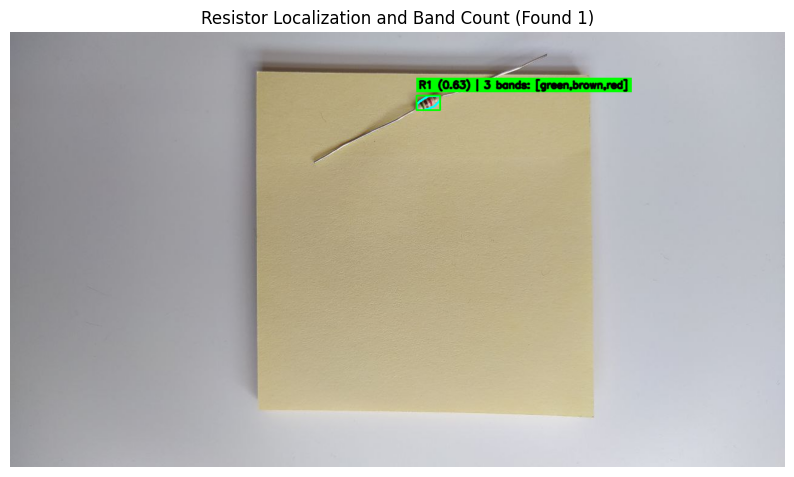

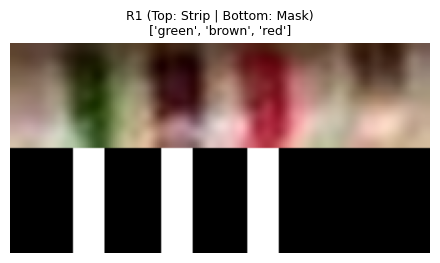

In [ ]:
# --- Print Apple Image with Boxes & Confidence ---
#VisualizationModule.show_apple_results(
#    bgr_image=apple_img,
#    verified_apples=verified_apples,
#    total_count=total_apples,
#)

# --- Print Resistor Image (e.g., 1.jpeg) with Boxes, Confidence & Deskewed Crops ---
VisualizationModule.show_resistor_results(
    bgr_image=res_img,
    raw_resistors=raw_resistors,
    extracted_resistors=extracted_bands,
    resistor_summary=resistor_summary,
)

## 10.3 resistor pipeline II
Resistor pipeline using the learned detector and classifier.

In [ ]:
# Resistor pipeline with the method II (learned detector + learned colour)
# Can't run until train the new yolo model with our dataset, use the next cell.
extracted_bands_v2 = PostProcessingV2.resistor_postprocessing(res_img, raw_resistors)
resistor_summary_v2 = ClassificationCountingModuleV2.classify_and_count_resistor_bands(
    extracted_bands_v2, use_iec=True)

for res in resistor_summary_v2:
    print(f"Resistor #{res['resistor_id']} | Total Bands: {res['total_bands']} | "
          f"Tally: {res['color_tally']} | Sequence: {res['ordered_bands']}")

VisualizationModule.show_resistor_results(res_img, raw_resistors, extracted_bands_v2, resistor_summary_v2)


NameError: name 'res_img' is not defined

# 11.Single-image inference for resistor

IMG_20261023_090800791_jpg.rf.341d9c4e660e57e2620b6d560777e408.jpg: 5 GT resistors
Resistor #1 | Total Bands: 4 | Tally: {'brown': 1, 'black': 1, 'green': 1, 'gold': 1} | Sequence: ['brown', 'black', 'green', 'gold']
Resistor #2 | Total Bands: 4 | Tally: {'brown': 1, 'black': 1, 'orange': 1, 'gold': 1} | Sequence: ['brown', 'black', 'orange', 'gold']
Resistor #3 | Total Bands: 3 | Tally: {'orange': 1, 'yellow': 1, 'gold': 1} | Sequence: ['orange', 'yellow', 'gold']
Resistor #4 | Total Bands: 5 | Tally: {'orange': 2, 'red': 1, 'brown': 2} | Sequence: ['orange', 'red', 'brown', 'orange', 'brown']
Resistor #5 | Total Bands: 4 | Tally: {'brown': 1, 'orange': 1, 'red': 1, 'blue': 1} | Sequence: ['brown', 'orange', 'red', 'blue']


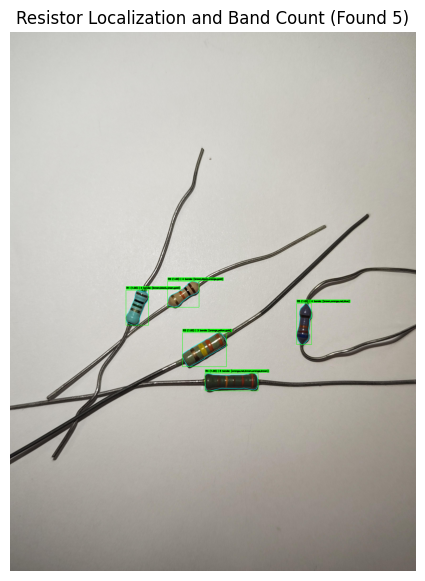

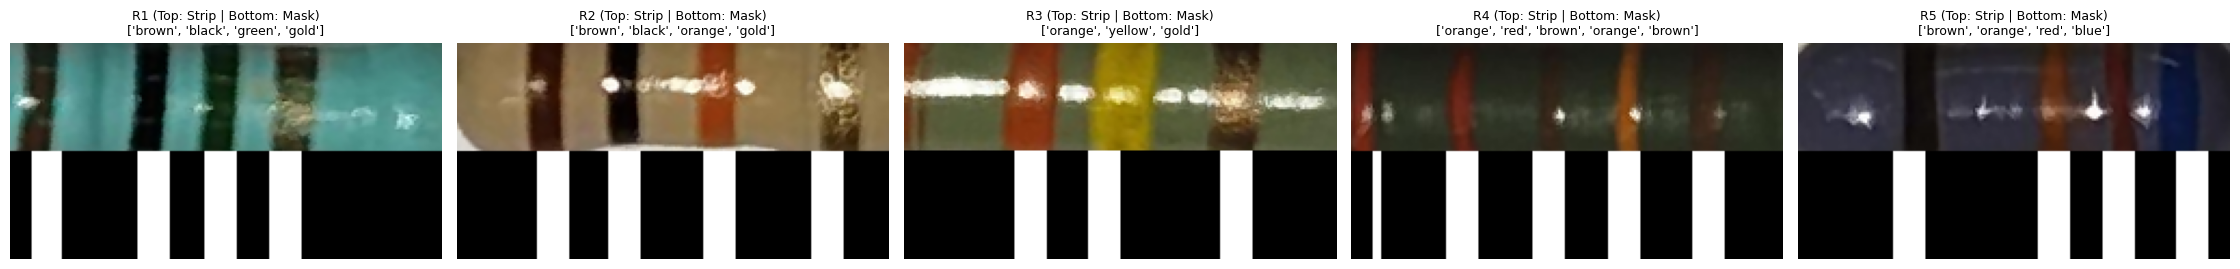

In [ ]:
# ============================================================================
# TEMP: single-image inference for the NEW method, using GT polygons
#
# This cell demonstrates the COLOUR stage only: the resistor polygons are
# supplied by you (or read from a YOLO-format label), so detection quality does
# not affect the result.
#
# 1) Set INFER_IMAGE_PATH.
# 2) Either set GT_LABEL_PATH to a YOLO-segmentation .txt, or fill GT_POLYGONS
#    with pixel-coordinate polygons (one list per resistor).
# ============================================================================
from pathlib import Path
import cv2
import numpy as np

INFER_IMAGE_PATH = Path("/content/drive/MyDrive/Mashine_vision/IMG_20261023_090800791_jpg.rf.341d9c4e660e57e2620b6d560777e408.jpg")    # <-- REPLACE
GT_LABEL_PATH = Path("/content/drive/MyDrive/Mashine_vision/IMG_20261023_090800791_jpg.rf.341d9c4e660e57e2620b6d560777e408.txt")       # <-- REPLACE (optional)

# If you have no label file, fill polygons here: one list of (x, y) per resistor.
GT_POLYGONS = [
    # [(120, 240), (300, 250), (310, 320), (130, 310)],
    # [(400, 500), (520, 505), (515, 560), (395, 555)],
]


def load_yolo_gt(label_path, W, H, conf=1.0):
    """Read a YOLO segmentation label file into the pipeline's instance format."""
    instances = []
    if not label_path.exists():
        return instances
    for line in label_path.read_text(encoding="utf-8").splitlines():
        t = line.strip().split()
        if len(t) < 7:
            continue
        xs = np.array(t[1::2], dtype=float) * W
        ys = np.array(t[2::2], dtype=float) * H
        instances.append({
            "conf": conf,
            "bbox": (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())),
            "polygon": np.column_stack([xs, ys]).astype(np.float32),
        })
    return instances


def instances_from_polygons(polygons, conf=1.0):
    """Build instances from hand-filled pixel-coordinate polygons."""
    out = []
    for pts in polygons:
        arr = np.asarray(pts, dtype=np.float32)
        if len(arr) < 3:
            continue
        out.append({
            "conf": conf,
            "bbox": (int(arr[:, 0].min()), int(arr[:, 1].min()),
                     int(arr[:, 0].max()), int(arr[:, 1].max())),
            "polygon": arr,
        })
    return out


res_img = cv2.imread(str(INFER_IMAGE_PATH))
assert res_img is not None, f"Cannot read {INFER_IMAGE_PATH}"
H, W = res_img.shape[:2]

raw_resistors = load_yolo_gt(GT_LABEL_PATH, W, H)
if not raw_resistors and GT_POLYGONS:
    raw_resistors = instances_from_polygons(GT_POLYGONS)
if not raw_resistors:
    raise ValueError("No GT supplied: set GT_LABEL_PATH or fill GT_POLYGONS.")

print(f"{INFER_IMAGE_PATH.name}: {len(raw_resistors)} GT resistors")

extracted_bands = PostProcessingV2.resistor_postprocessing(res_img, raw_resistors)
resistor_summary = ClassificationCountingModuleV2.classify_and_count_resistor_bands(
    extracted_bands, use_iec=True)

for res in resistor_summary:
    print(f"Resistor #{res['resistor_id']} | Total Bands: {res['total_bands']} | "
          f"Tally: {res['color_tally']} | Sequence: {res['ordered_bands']}")

VisualizationModule.show_resistor_results(res_img, raw_resistors,
                                          extracted_bands, resistor_summary)


# 12.Classical segmentation

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

class ClassicalResistorSegmentation:
    @staticmethod
    def segment(original_bgr):
        img_h, img_w = original_bgr.shape[:2]

        blurred = cv2.GaussianBlur(original_bgr, (5, 5), 0)

        gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)

        edges = cv2.Canny(gray, 40, 120)

        kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
        closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel_close)

        kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
        wire_free_mask = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel_open)

        cv2_imshow(wire_free_mask)


        contours, _ = cv2.findContours(wire_free_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        raw_resistors = []
        crops = []

        for cnt in contours:
            area = cv2.contourArea(cnt)
            x, y, w, h = cv2.boundingRect(cnt)

            if area < 300:
                continue

            if area > 0.5 * (img_h * img_w):
                continue

            hull = cv2.convexHull(cnt)
            hull_area = cv2.contourArea(hull)
            if hull_area == 0: continue
            solidity = float(area) / hull_area
            if solidity < 0.4:
                continue

            aspect_ratio = max(w, h) / float(min(w, h))
            if aspect_ratio < 1.2 or aspect_ratio > 7.0:
                continue
            epsilon = 0.02 * cv2.arcLength(cnt, True)
            approx = cv2.approxPolyDP(cnt, epsilon, True)

            if len(approx) < 3:
                approx = cv2.convexHull(cnt)

            if len(approx) >= 3:
                raw_resistors.append({
                    "conf": 1.0,
                    "bbox": (x, y, x + w, y + h),
                    "polygon": approx.reshape(-1, 2).astype(np.float32)
                })
                crops.append(original_bgr[y:y+h, x:x+w].copy())

        return raw_resistors, crops

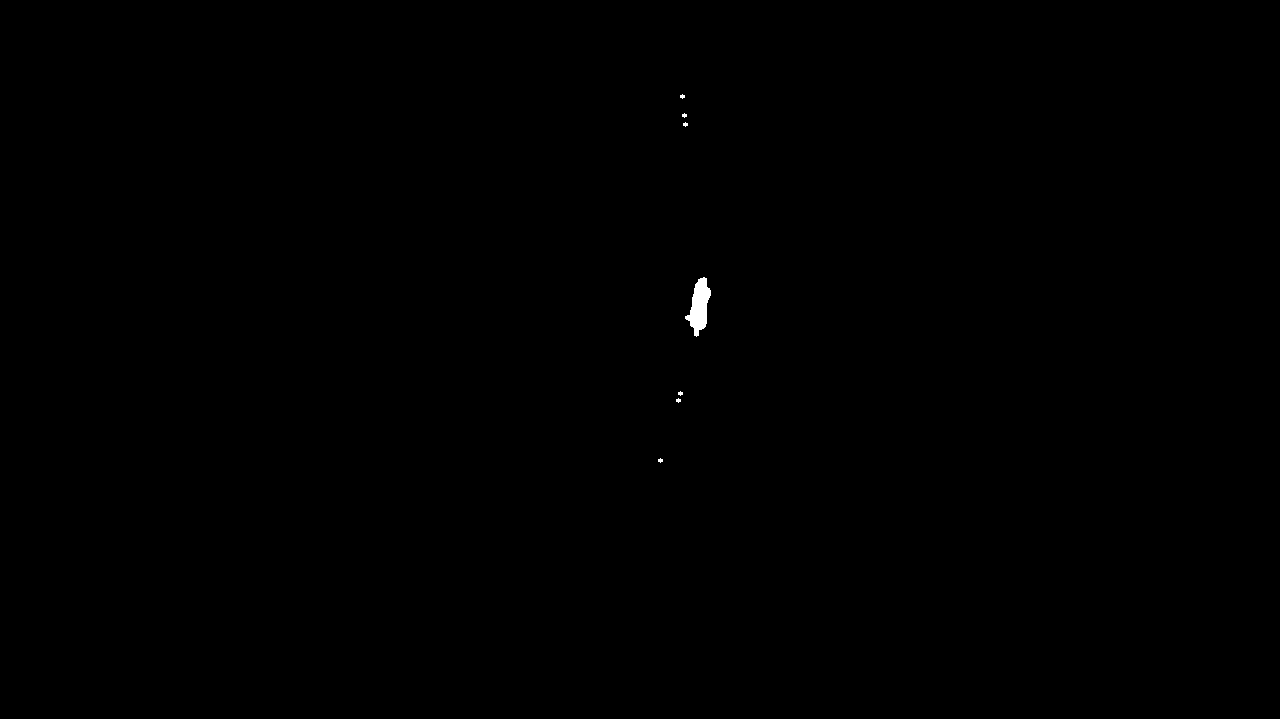

Classical CV found 1 potential objects.
Classical R1: bbox=(685, 277, 711, 337), crop=(60, 26, 3)
Resistor #1 | Total Bands: 4 | Tally: {'red': 1, 'orange': 2, 'gold': 1} | Sequence: ['red', 'orange', 'gold', 'orange']


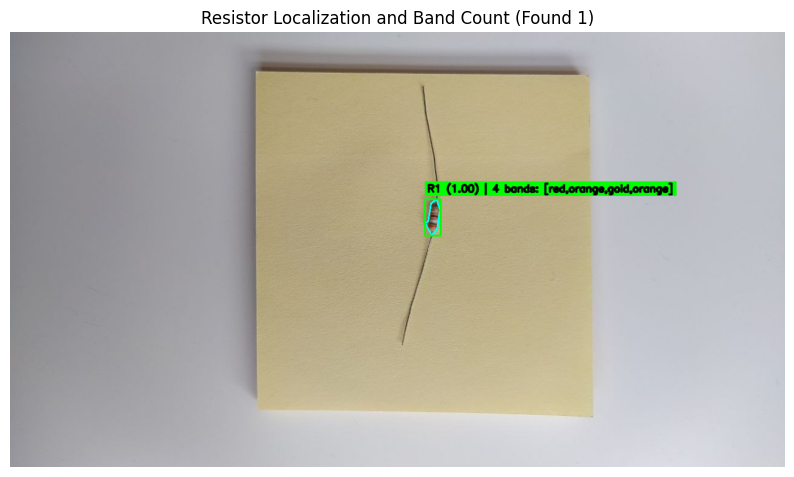

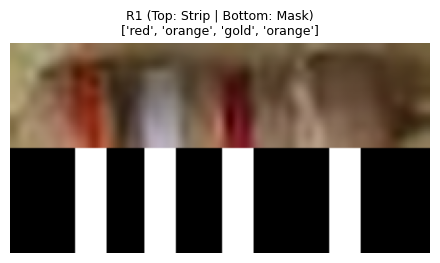

In [ ]:
# Classical Resistor Pipeline Execution
classical_segmenter = ClassicalResistorSegmentation()

sample_resistor_path = resistor_images_dir / resistor_splits["test"][11]
res_img = cv2.imread(str(sample_resistor_path))

raw_resistors, resistor_crops = classical_segmenter.segment(res_img)

print(f"Classical CV found {len(raw_resistors)} potential objects.")
for i, res in enumerate(raw_resistors):
    print(f"Classical R{i + 1}: bbox={res['bbox']}, crop={resistor_crops[i].shape}")

extracted_bands = PostProcessing.resistor_postprocessing(res_img, raw_resistors)

resistor_summary = ClassificationCountingModule.classify_and_count_resistor_bands(extracted_bands)

for res in resistor_summary:
    print(f"Resistor #{res['resistor_id']} | Total Bands: {res['total_bands']} | "
          f"Tally: {res['color_tally']} | Sequence: {res['ordered_bands']}")

VisualizationModule.show_resistor_results(res_img, raw_resistors, extracted_bands, resistor_summary)